<a href="https://colab.research.google.com/github/agyl05/analisis-kemiskinan-bps/blob/main/clear_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt

In [2]:

up = files.upload()
nama_file = list(up.keys())[0]
raw = pd.read_csv(nama_file, header=None)
raw.shape

Saving Query Builder Result - Jumat, 30 Oktober 2026 pukul 21.25.47 WIB.csv to Query Builder Result - Jumat, 30 Oktober 2026 pukul 21.25.47 WIB.csv


(45, 109)

In [3]:
wilayah  = raw.iloc[1, 1:].ffill()
tahun    = raw.iloc[2, 1:].ffill()
semester = raw.iloc[3, 1:]

data = raw.iloc[4:].copy()
data = data[data[0].notna() & (data[0] !="catatan")]
data.columns = ["provinsi"] + list (range(1, raw.shape[1]))

df = data.melt(id_vars="provinsi", var_name="kolom", value_name="persen_miskin")
df["wilayah"]  = df ["kolom"].map(wilayah)
df["tahun"]    = df ["kolom"].map(tahun).astype(int)
df["semester"] = df ["kolom"].map(semester)

In [4]:
# Membuat ulang df dari raw untuk memastikan data segar (tidak rusak akibat eksekusi berulang)
df = data.melt(id_vars="provinsi", var_name="kolom", value_name="persen_miskin")
df["wilayah"]  = df["kolom"].map(wilayah)
df["tahun"]    = df["kolom"].map(tahun).astype(int)
df["semester"] = df["kolom"].map(semester)

# Memfilter data tahunan dan membersihkan kolom
df = df[df["semester"] != "Tahunan"].drop(columns="kolom", errors="ignore")
df["persen_miskin"] = pd.to_numeric(df["persen_miskin"], errors="coerce")

# Ekstrak digit semester secara aman
df["semester"] = df["semester"].astype(str).str.extract(r"(\d)")[0].astype("Int64")
df = df[["provinsi", "wilayah", "tahun", "semester", "persen_miskin"]].reset_index(drop=True)

print(df.shape, df["persen_miskin"].isna().sum())
df.head()

(2880, 5) 531


,provinsi,wilayah,tahun,semester,persen_miskin
0,ACEH,Perkotaan,2015,1,11.13
1,SUMATERA UTARA,Perkotaan,2015,1,10.16
2,SUMATERA BARAT,Perkotaan,2015,1,5.73
3,RIAU,Perkotaan,2015,1,6.79
4,JAMBI,Perkotaan,2015,1,11.60


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2880 entries, 0 to 2879
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   provinsi       2880 non-null   object 
 1   wilayah        2880 non-null   object 
 2   tahun          2880 non-null   int64  
 3   semester       2880 non-null   Int64  
 4   persen_miskin  2349 non-null   float64
dtypes: Int64(1), float64(1), int64(1), object(2)
memory usage: 115.4+ KB


In [6]:
kosong = df[df["persen_miskin"].isna()]
kosong.groupby(["tahun", "semester"]).size()

tahun  semester
2015   1            16
       2            16
2016   1            16
       2            15
2017   1            16
       2            16
2018   1            16
       2            16
2019   1            16
       2            16
2020   1            16
       2            16
2021   1            16
       2            16
2022   1            16
       2            16
2023   1            16
       2           120
2024   1             4
       2             4
2025   1             4
       2             4
2026   1             4
       2           120
dtype: int64

In [7]:
df.duplicated(["provinsi", "wilayah", "tahun", "semester"]).sum()

np.int64(0)

In [8]:
print(df["provinsi"].nunique())
print(df["wilayah"].unique())
df["persen_miskin"].describe()

40
['Perkotaan' 'Perdesaan' 'Jumlah']


,persen_miskin
count,2349.000000
mean,10.439225
std,6.483494
min,0.000000
25%,5.890000
50%,8.760000
75%,12.810000
max,39.370000


In [9]:
df.groupby("provinsi")["persen_miskin"].count().sort_values().head(6)

,persen_miskin
provinsi,
Catatan,0
PAPUA TENGAH,15
PAPUA SELATAN,15
PAPUA PEGUNUNGAN,15
PAPUA BARAT DAYA,15
DKI JAKARTA,45


In [10]:
jumlah_data = df.groupby("provinsi")["persen_miskin"].count()
df = df[df["provinsi"].isin(jumlah_data[jumlah_data > 0].index)].reset_index(drop=True)

In [11]:
import numpy as np

df.loc[df["persen_miskin"] == 0, "persen_miskin"] = np.nan

In [12]:
print(df.shape, df["persen_miskin"].isna().sum(), df["provinsi"].nunique())

(2808, 5) 460 39


In [13]:
from google.colab import files

df.to_csv("kemiskinan_provinsi.csv", index=False)
files.download("kemiskinan_provinsi.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

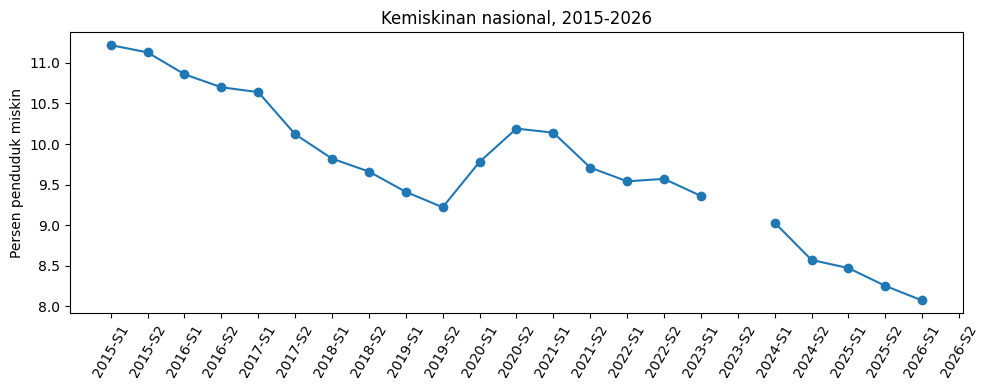

In [14]:
nasional = df[(df["provinsi"] == "INDONESIA") & (df["wilayah"] == "Jumlah")].copy()
nasional["periode"] = nasional["tahun"].astype(str) + "-S" + nasional["semester"].astype(str)

plt.figure(figsize=(10, 4))
plt.plot(nasional["periode"], nasional["persen_miskin"], marker="o")
plt.xticks(rotation=60)
plt.ylabel("Persen penduduk miskin")
plt.title("Kemiskinan nasional, 2015-2026")
plt.tight_layout()
plt.show()

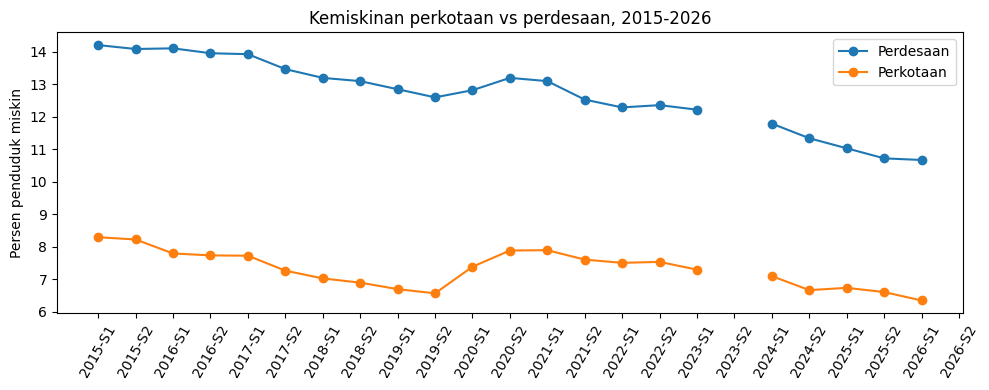

In [15]:
dk = df[(df["provinsi"] == "INDONESIA") & (df["wilayah"].isin(["Perkotaan", "Perdesaan"]))].copy()
dk["periode"] = dk["tahun"].astype(str) + "-S" + dk["semester"].astype(str)

plt.figure(figsize=(10, 4))
for nama, kelompok in dk.groupby("wilayah"):
    plt.plot(kelompok["periode"], kelompok["persen_miskin"], marker="o", label=nama)
plt.xticks(rotation=60)
plt.ylabel("Persen penduduk miskin")
plt.title("Kemiskinan perkotaan vs perdesaan, 2015-2026")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
from google.colab import files

df.to_excel("kemiskinan_provinsi.xlsx", index=False)
files.download("kemiskinan_provinsi.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>